# Seat Relay: no-show model

This notebook shows the data side of Seat Relay, a concept entry for the FC Bayern Fan AI-DEATION competition. It answers one question: **can a club predict, from a season-ticket holder's own turnstile scans, which seats are likely to go empty, and target a Gemini nudge at those holders only?**

**All data here is synthetic.** FC Bayern publishes no no-show rate, season-ticket count or exchange volume. The generator in `synth.py` encodes behaviour reported in published research on season-ticket no-shows (habit, kick-off slot, fixture appeal, travel distance), and every behavioural assumption in the simulation is a named parameter you can change.

The model uses only data about the holder and the fixture: no seat neighbours, no friends, no other fan's behaviour. Its output decides **who gets asked**, never who gets penalised.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
import synth

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
RED, INK, GREY = "#c4122f", "#1b1517", "#b8adb0"

df = synth.add_history_features(synth.build(n_holders=4000, seed=7))
print(f"{df.holder_id.nunique():,} synthetic holders x {df.fixture_id.nunique()} home fixtures = {len(df):,} seats")
print(f"Overall no-show rate: {df.no_show.mean():.1%}")

4,000 synthetic holders x 44 home fixtures = 176,000 seats
Overall no-show rate: 10.0%


## 1. Where empty seats come from
In the synthetic data, as in the research, empty seats cluster in late midweek kick-offs and low-appeal fixtures.

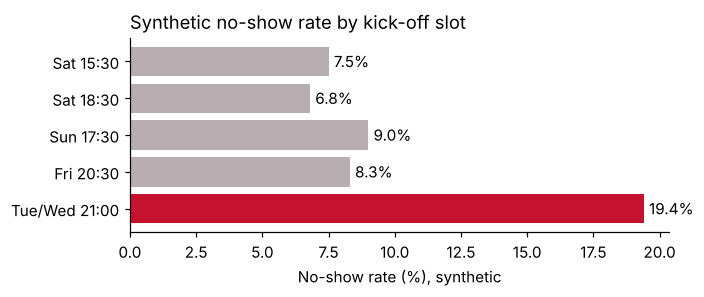

slot
Sat 15:30         7.5
Sat 18:30         6.8
Sun 17:30         9.0
Fri 20:30         8.3
Tue/Wed 21:00    19.4
Name: no_show, dtype: float64

In [2]:
by_slot = (df.groupby("slot").no_show.mean()
           .reindex(list(synth.SLOTS)).mul(100).round(1))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(by_slot.index, by_slot.values, color=[RED if "Tue" in s else GREY for s in by_slot.index])
for y, v in enumerate(by_slot.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center")
ax.set_xlabel("No-show rate (%), synthetic"); ax.invert_yaxis()
ax.set_title("Synthetic no-show rate by kick-off slot", loc="left")
plt.tight_layout(); plt.savefig("figures/noshow_by_slot.png"); plt.show()
by_slot

## 2. Train on season 1, test on season 2
Features are computable before kick-off from the holder's own scan history and the fixture. The first five games of the dataset are dropped so every row has some history.

In [3]:
NUM = ["attended_last13", "attend_rate_prior", "midweek_attend_rate_prior",
       "same_slot_missed_streak", "opponent_appeal", "tenure_years", "age"]
CAT = ["slot", "competition", "domicile"]
data = df[df.games_seen >= 5]
train, test = data[data.season == 1], data[data.season == 2]

prep = ColumnTransformer([("num", StandardScaler(), NUM),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
models = {
    "Logistic regression": make_pipeline(prep, LogisticRegression(max_iter=1000)),
    "Gradient boosting": make_pipeline(prep, HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=0)),
}
results = {}
for name, m in models.items():
    m.fit(train[NUM + CAT], train.no_show)
    p = m.predict_proba(test[NUM + CAT])[:, 1]
    results[name] = p
    print(f"{name:22s} AUC {roc_auc_score(test.no_show, p):.3f}   Brier {brier_score_loss(test.no_show, p):.4f}")
test = test.assign(p_noshow=results["Logistic regression"])

Logistic regression    AUC 0.750   Brier 0.0740


Gradient boosting      AUC 0.755   Brier 0.0740


Logistic regression is the default choice here: close to the boosted model on this data, and every coefficient can be explained to a fan, a data protection officer or a judge. That matters more for this use case than a small accuracy gain.

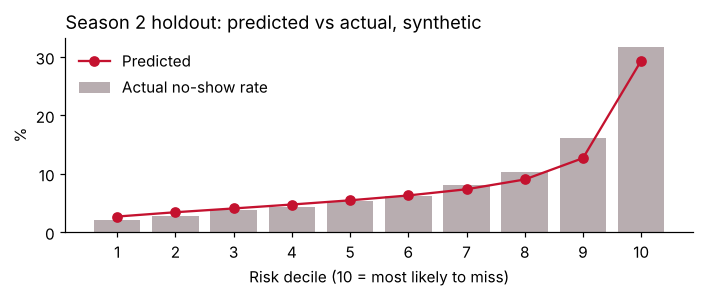

Top decile holds 35% of all empty seats in season 2


,predicted,actual
decile,,
1,2.7,2.1
2,3.4,2.7
3,4.1,3.9
4,4.7,4.4
5,5.5,5.3
6,6.3,6.2
7,7.4,8.0
8,9.0,10.4
9,12.7,16.2


In [4]:
test["decile"] = pd.qcut(test.p_noshow.rank(method="first"), 10, labels=range(1, 11))
cal = test.groupby("decile", observed=True).agg(predicted=("p_noshow", "mean"), actual=("no_show", "mean")) * 100
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.bar(cal.index.astype(int), cal.actual, color=GREY, label="Actual no-show rate")
ax.plot(cal.index.astype(int), cal.predicted, color=RED, marker="o", label="Predicted")
ax.set_xlabel("Risk decile (10 = most likely to miss)"); ax.set_ylabel("%")
ax.set_xticks(range(1, 11)); ax.legend(frameon=False)
ax.set_title("Season 2 holdout: predicted vs actual, synthetic", loc="left")
plt.tight_layout(); plt.savefig("figures/calibration.png"); plt.show()
top = test[test.decile == 10]
print(f"Top decile holds {top.no_show.sum() / test.no_show.sum():.0%} of all empty seats in season 2")
cal.round(1)

## 3. Who to nudge, and what it recovers

This is a simulation, and its behaviour parameters are **assumptions, not findings**. They are set to match the direction of the Bundesliga field experiment reported by ESSMA (April 2025): generic reminders had no measurable effect, a reminder plus a high-value incentive reduced no-shows, and holders who had attended 5 to 7 of the previous 13 matches responded most.

For each season 2 fixture, compare three policies: today's exchange with no nudge, a nudge to every holder, and a nudge only to the holders the model ranks as most likely to miss.

In [5]:
ASSUME = {
    "baseline_release": 0.10,      # share of no-shows who list on the exchange today, unprompted
    "reminder_only_lift": 0.00,    # extra release from a plain reminder (study: no effect)
    "incentive_release": 0.35,     # release rate among nudged no-shows offered relay credit
    "incentive_release_mid": 0.50, # same, for holders who attended 5 to 7 of last 13
}
rng = np.random.default_rng(1)
test["mid_segment"] = test.attended_last13.between(5, 7)

def simulate(policy, top_share=0.15):
    t = test.copy()
    if policy == "none":
        t["nudged"] = False
    elif policy == "everyone":
        t["nudged"] = True
    else:
        t["rank"] = t.groupby("fixture_id").p_noshow.rank(ascending=False, pct=True)
        t["nudged"] = t["rank"] <= top_share
    rate = np.where(t.nudged, np.where(t.mid_segment, ASSUME["incentive_release_mid"], ASSUME["incentive_release"]),
                    ASSUME["baseline_release"])
    released = (t.no_show == 1) & (rng.uniform(size=len(t)) < rate)
    return {"Nudges sent": int(t.nudged.sum()),
            "Nudges to fans who came anyway": int((t.nudged & (t.no_show == 0)).sum()),
            "Seats relayed": int(released.sum()),
            "Empty seats left": int(((t.no_show == 1) & ~released).sum())}

table = pd.DataFrame({"Exchange only": simulate("none"),
                      "Nudge everyone": simulate("everyone"),
                      "Seat Relay (top 15% risk)": simulate("targeted")}).T
table["Seats relayed per 100 nudges"] = (table["Seats relayed"] / table["Nudges sent"].replace(0, np.nan) * 100).round(1)
table

,Nudges sent,Nudges to fans who came anyway,Seats relayed,Empty seats left,Seats relayed per 100 nudges
Exchange only,0,0,807,7187,NaN
Nudge everyone,88000,80006,2864,5130,3.3
Seat Relay (top 15% risk),13200,10079,1676,6318,12.7


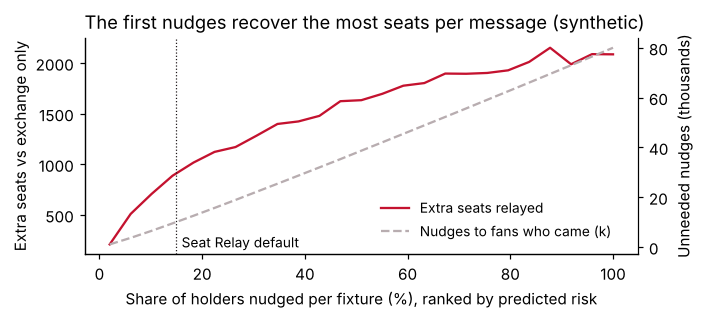

In [6]:
shares = np.linspace(0.02, 1.0, 25)
curve = pd.DataFrame([{**simulate("targeted", s), "share": s} for s in shares])
base = simulate("none")["Seats relayed"]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(curve.share * 100, curve["Seats relayed"] - base, color=RED, label="Extra seats relayed")
ax2 = ax.twinx()
ax2.plot(curve.share * 100, curve["Nudges to fans who came anyway"] / 1000, color=GREY, ls="--", label="Nudges to fans who came (k)")
ax.set_xlabel("Share of holders nudged per fixture (%), ranked by predicted risk")
ax.set_ylabel("Extra seats vs exchange only"); ax2.set_ylabel("Unneeded nudges (thousands)")
ax.axvline(15, color=INK, lw=0.8, ls=":"); ax.text(16, ax.get_ylim()[1] * 0.08, "Seat Relay default", fontsize=9)
ax.spines["right"].set_visible(True)
ax.set_title("The first nudges recover the most seats per message (synthetic)", loc="left")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.22), frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("figures/targeting_curve.png"); plt.show()

## 4. From score to a Gemini message

Gemini never sees the raw scan log or the score. It receives a short, structured payload of facts about this holder and this fixture, with a plain-language reason, and writes the message in the holder's language. The numbers in the message come from the payload, so the model cannot invent them. The prompt template is in `prompts/nudge_prompt.md`.

In [7]:
def reason(row):
    if row.slot == "Tue/Wed 21:00" and row.same_slot_missed_streak >= 2:
        return f"missed the last {int(row.same_slot_missed_streak)} Tuesday or Wednesday 21:00 home games"
    if row.attended_last13 <= 7:
        return f"attended {int(row.attended_last13)} of the last 13 home games"
    return "has a lower than usual attendance pattern for this kind of fixture"

ex = (test[(test.slot == "Tue/Wed 21:00") & (test.same_slot_missed_streak >= 2) & test.mid_segment]
      .sort_values("p_noshow", ascending=False).iloc[0])
payload = {
    "holder_first_name": "Lukas",            # example name, not from data
    "language": "de",
    "fixture": {"opponent": "Union Berlin", "competition": ex.competition, "kickoff": ex.slot},
    "seat": "Block 112, Row 18, Seat 9",
    "reason": reason(ex),
    "reward": "1 relay credit toward away and cup ballots",
    "release_deadline": "24 hours before kick-off",
}
print(f"Holder {ex.holder_id}: predicted no-show {ex.p_noshow:.0%}, attended {int(ex.attended_last13)} of last 13")
print(json.dumps(payload, indent=2, ensure_ascii=False))

Holder H03766: predicted no-show 94%, attended 5 of last 13
{
  "holder_first_name": "Lukas",
  "language": "de",
  "fixture": {
    "opponent": "Union Berlin",
    "competition": "DFB-Pokal",
    "kickoff": "Tue/Wed 21:00"
  },
  "seat": "Block 112, Row 18, Seat 9",
  "reason": "missed the last 6 Tuesday or Wednesday 21:00 home games",
  "reward": "1 relay credit toward away and cup ballots",
  "release_deadline": "24 hours before kick-off"
}


## 5. Guardrails built into the design

- **Opt-in only.** Holders choose to receive relay messages.
- **Reward-only.** The score can unlock credit, priority and upgrades. It is never an input to cancellation, sanctions or attendance-minimum checks, which keeps it clear of GDPR Article 22 on significant automated decisions.
- **Own data only.** Features come from the holder's own scans and the fixture. No neighbours, no friends, no cross-fan disclosure.
- **Explainable.** Logistic regression, and every message states the real reason it was sent.
- **Measured honestly.** A pilot would run on midweek fixtures against a control group, tracking seat use, seats relayed and opt-out rate after each nudge.

Real sizing needs Bayern's own scan and exchange data. This notebook shows the method, not the size of the prize.